# Нечеткая логика

**Цель лабораторной работы:** знакомство с основами нечеткой логики и реализация алгоритма нечеткого вывода Мамдани с использованием библиотеки `simpful`.

**Задачи лабораторной работы:**

1.  Построить графики функций принадлежности для оценки качества еды и количества чаевых.
2.  Изменить шкалу оценок и диапазон процента чаевых.
3.  Построить зависимость изменения процента чаевых от оценки качества сервиса.
4.  Построить зависимость изменения процента чаевых от оценки качества еды.

Математическая теория нечетких множеств (fuzzy sets) и [нечеткая логика (fuzzy logic)](https://loginom.ru/blog/fuzzy-logic) являются обобщениями классической теории множеств и классической формальной логики. Данные понятия были впервые предложены американским ученым Лотфи Заде (Lotfi Zadeh) в 1965 г. Основной причиной появления новой теории стало наличие нечетких и приближенных рассуждений при описании человеком процессов, систем, объектов.

В нечеткой логике, в отличие от классической (бинарной), вместо величин истина и ложь используется величина степень истинности, принимающая любые значения из бесконечного множества от 0 до 1 включительно.

Для определения нечетких значений существует [ряд алгоритмов (Mamdani, Tsukamoto, Sugeno и пр.)](https://neuronus.com/theory/fl/308-nechetkie-vyvody.html?ysclid=lawtaj0ww924607942).

## Алгоритм нечеткой логики Mamdani
В текущей работе рассмотрен алгоритм Мамдани. [Нечеткий вывод](https://www.mathworks.com/help/fuzzy/fuzzy-inference-process.html) Мамдани был впервые представлен как метод создания системы управления путем синтеза набора лингвистических правил управления, полученных от опытных людей-операторов. В системе Мамдани результатом каждого правила является нечеткое множество. Поскольку системы Мамдани имеют более интуитивные и простые для понимания базы правил, они хорошо подходят для приложений экспертных систем, где правила создаются на основе экспертных знаний человека, таких как медицинская диагностика. Процесс вывода системы Мамдани обобщен на следующем рисунке.

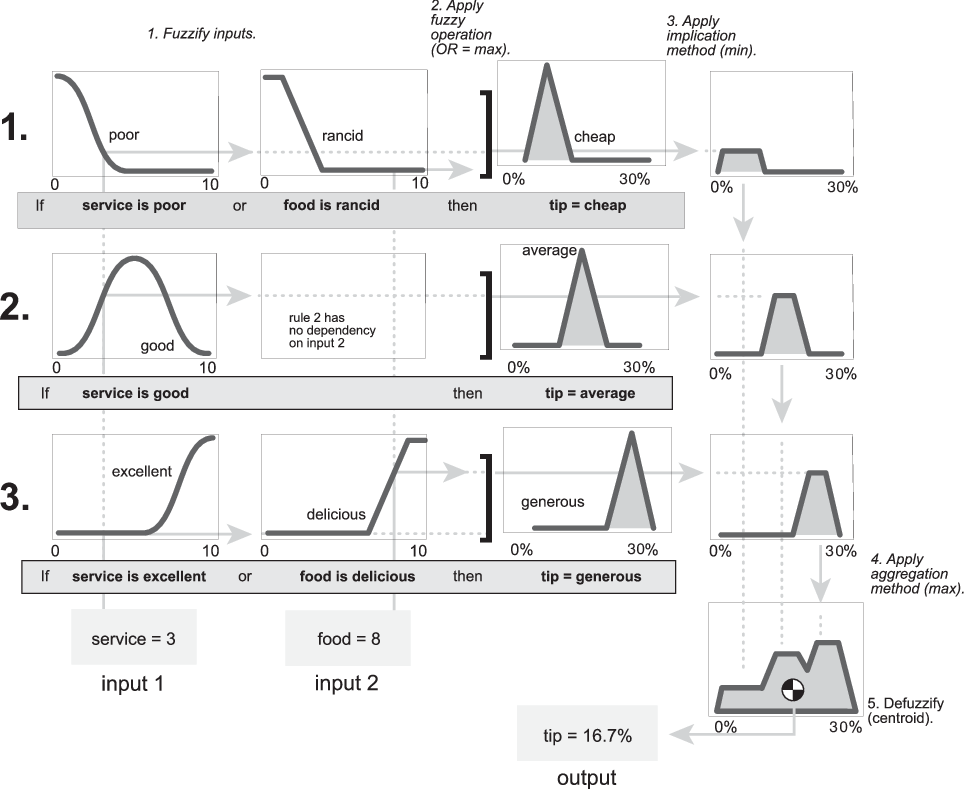

Результатом каждого правила является нечеткое множество, полученное из выходной функции принадлежности и метода импликации FIS (Этап 3). Эти выходные нечеткие множества объединяются в одно нечеткое множество с использованием метода агрегирования FIS (Этап 4). Затем, чтобы вычислить окончательное четкое выходное значение, комбинированный выходной нечеткий набор дефаззифицируется с использованием одного из [методов дефаззификации](https://www.mathworks.com/help/fuzzy/defuzzification-methods.html) (Этап 5).

# Реализация алгоритма нечеткой логики Mamdani (библиотека simpful)

## Установка библиотеки нечеткой логики simpful

In [ ]:
!pip install simpful==2.7.0

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/


## Программа определения количества чаевых
Представленнвя ниже программа вычисляет процет чаевых при заданной оценке уровня сервиса и качества еды.

  ____  __  _  _  ____  ____  _  _  __   
 / ___)(  )( \/ )(  _ \(  __)/ )( \(  ) v2.7.0 
 \___ \ )( / \/ \ ) __/ ) _) ) \/ (/ (_/\ 
 (____/(__)\_)(_/(__)  (__)  \____/\____/

 Created by Marco S. Nobile (m.s.nobile@tue.nl)
 and Simone Spolaor (simone.spolaor@unimib.it)

{'Tip': 14.17223614042091}


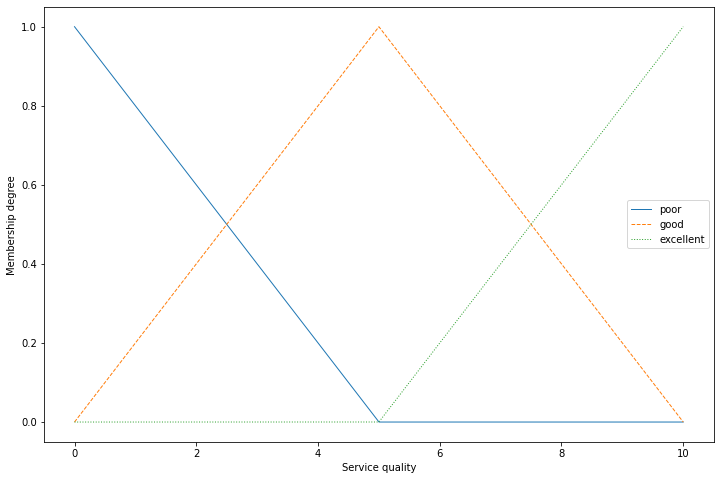

In [ ]:
from simpful import *
import matplotlib.pyplot as plt

# Простая система нечеткого вывода для задачи рассчета чаевых
# Создаем объект нечеткой логики
FS = FuzzySystem()

# Создаем нечеткие множества и лингвистические переменные
S_1 = FuzzySet(function=Triangular_MF(a=0, b=0, c=5), term="poor")
S_2 = FuzzySet(function=Triangular_MF(a=0, b=5, c=10), term="good")
S_3 = FuzzySet(function=Triangular_MF(a=5, b=10, c=10), term="excellent")

# Создаем переменную LV1 для хранения лингвистических переменных
LV1 = LinguisticVariable([S_1,S_2, S_3], concept="Service quality", universe_of_discourse=[0,10], )

# Добавляем лингвистическую переменную в объект (модель) нечетной логики
FS.add_linguistic_variable("Service", LV1)

# Строим графики функций принадлежности для набора "Service quality"
fig2 = plt.figure(figsize=(12, 8))
ax = fig2.add_subplot()
LV1.draw(ax=ax)
plt.plot()

# Создаем нечеткие множества для оценки качества еды
F_1 = FuzzySet(function=Triangular_MF(a=0, b=0, c=10), term="rancid")
F_2 = FuzzySet(function=Triangular_MF(a=0, b=10, c=10), term="delicious")
FS.add_linguistic_variable("Food", LinguisticVariable([F_1, F_2], concept="Food quality", universe_of_discourse=[0,10]))

# Создаем нечеткие множества и лингвистические переменные
T_1 = FuzzySet(function=Triangular_MF(a=0, b=0, c=10), term="small")
T_2 = FuzzySet(function=Triangular_MF(a=0, b=10, c=20), term="average")
T_3 = FuzzySet(function=Trapezoidal_MF(a=10, b=20, c=25, d=25), term="generous")
FS.add_linguistic_variable("Tip", LinguisticVariable([T_1, T_2, T_3], universe_of_discourse=[0,25]))

# Задаем правил нечеткой логики
R1 = "IF (Service IS poor) OR (Food IS rancid) THEN (Tip IS small)"
R2 = "IF (Service IS good) THEN (Tip IS average)"
R3 = "IF (Service IS excellent) OR (Food IS delicious) THEN (Tip IS generous)"
FS.add_rules([R1, R2, R3])

# Устанавливаем тестовые значения
FS.set_variable("Service", 4)
FS.set_variable("Food", 8)

# Выполнение логического вывода Mamdani и вывод на печать
print(FS.Mamdani_inference(["Tip"]))

## Ссылки на литературу
1.   [Документация simpful](https://simpful.readthedocs.io/en/latest/index.html)
2.   [Статья по использованию библиотеки simpful по организации экспертных исстем "Simpful: A User-Friendly Python Library for Fuzzy Logic"](https://www.atlantis-press.com/journals/ijcis/125945415/view)
3.  [Основы нечеткой логики, логико-лингвистические модели](http://www.itlab.unn.ru/fuzzylogic/fuz_logic.pdf)
4.   [Нечеткая логика на практике](https://habr.com/ru/post/125614/)